In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (Input, Dense, Embedding, Flatten, Concatenate, GRU, Lambda)
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [3]:
symbols = ["AAPL","AIG","BAC","GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(
        f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx",
        parse_dates=[0]
    )
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Δημιουργία Next_Close
    df["Next_Close"] = df.iloc[:, 3].shift(-1)
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

# Features και target
X_close_num = dataset.iloc[:, [0,1,2,4,5,6,7,8,9,10,11,12,14]]
X_close_sym = dataset["Symbol_enc"]
y_close = np.log1p(dataset["Next_Close"])

In [4]:
print(X_close_num)
print(X_close_sym)
print(y_close)

                 Open       High        Low     Volume      RSI      SMA  \
Date                                                                       
2019-01-02  36.985080  37.930661  36.827482  148158800  38.1140  44.1389   
2019-01-03  34.379965  34.795449  33.907176  365248800  27.9036  43.7742   
2019-01-04  34.511295  35.471204  34.336985  234428400  35.1259  43.4322   
2019-01-07  35.507026  35.538069  34.838433  219111200  34.9211  43.0787   
2019-01-08  35.712380  36.252032  35.464047  164101200  38.2354  42.7750   
...               ...        ...        ...        ...      ...      ...   
2024-12-23   6.140000   6.220000   6.015000    1077400  41.1601   6.8092   
2024-12-24   6.150000   6.220000   5.940000     596000  43.2908   6.8016   
2024-12-26   6.160000   6.670000   6.070000    1787300  49.6211   6.7962   
2024-12-27   6.510000   6.770000   6.360000    1684400  47.2697   6.7808   
2024-12-30   6.180000   6.240000   5.820000    2371700  40.3978   6.7592   

           

In [5]:
# GRU parameters
TIMESTEPS = 10

def create_sequences(X_close_num, X_close_sym, y_close, timesteps):
    Xn, Xs, yt = [], [], []

    for sym in np.unique(X_close_sym):
        mask = (X_close_sym == sym)

        X_close_sym_df = X_close_num.loc[mask].reset_index(drop=True)
        y_close_sym = y_close.loc[mask].reset_index(drop=True)

        for i in range(timesteps, len(X_close_sym_df)):
            Xn.append(X_close_sym_df.iloc[i-timesteps:i].values)
            Xs.append(sym)
            yt.append(y_close_sym.iloc[i])

    return np.array(Xn), np.array(Xs), np.array(yt)

In [6]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_close_num.loc[X_close_num.index.isin(train_dates)]
X_sym_train = X_close_sym.loc[X_close_sym.index.isin(train_dates)]
y_train = y_close.loc[y_close.index.isin(train_dates)]

X_num_test = X_close_num.loc[X_close_num.index.isin(test_dates)]
X_sym_test = X_close_sym.loc[X_close_sym.index.isin(test_dates)]
y_test = y_close.loc[y_close.index.isin(test_dates)]

train_dates_sorted = X_num_train.index.unique().sort_values()
val_len = int(len(train_dates_sorted) * 0.2)

train_dates_final = train_dates_sorted[:-val_len]
val_dates = train_dates_sorted[-val_len:]

X_num_train_final = X_close_num.loc[X_close_num.index.isin(train_dates_final)]
X_sym_train_final = X_close_sym.loc[X_close_sym.index.isin(train_dates_final)]
y_train_final = y_close.loc[y_close.index.isin(train_dates_final)]

X_num_val = X_close_num.loc[X_close_num.index.isin(val_dates)]
X_sym_val = X_close_sym.loc[X_close_sym.index.isin(val_dates)]
y_val = y_close.loc[y_close.index.isin(val_dates)]

In [7]:
# Feature scaling
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [8]:
# Sequences
Xn_train, Xs_train, y_train_seq = create_sequences( pd.DataFrame(X_num_train_final), X_sym_train_final.reset_index(drop=True), y_train_final.reset_index(drop=True), TIMESTEPS )
Xn_val, Xs_val, y_val_seq = create_sequences( pd.DataFrame(X_num_val), X_sym_val.reset_index(drop=True), y_val.reset_index(drop=True), TIMESTEPS )
Xn_test, Xs_test, y_test_seq = create_sequences( pd.DataFrame(X_num_test), X_sym_test.reset_index(drop=True), y_test.reset_index(drop=True), TIMESTEPS )

In [9]:
# Νευρωνικό Δίκτυο
num_input = Input(shape=(TIMESTEPS, Xn_train.shape[2]), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

sym_embed = Embedding(num_symbols, 4)(sym_input)
sym_embed = Flatten()(sym_embed)

time_positions = Lambda(lambda z: tf.tile(tf.reshape(tf.linspace(0.0, 1.0, tf.shape(z)[1]), (1, -1, 1)), [tf.shape(z)[0], 1, 1]))(num_input)

sequence_with_time = Concatenate(axis=-1)([num_input, time_positions])

x = GRU(64)(sequence_with_time)
x = Concatenate()([x, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model([num_input, sym_input], output)
model.compile(optimizer=Adam(0.001), loss="mean_squared_error", metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True )
history=model.fit([Xn_train, Xs_train],y_train_seq, validation_data=([Xn_val, Xs_val], y_val_seq), epochs=1000, batch_size=16, callbacks=[early_stopping])

Epoch 1/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.7237 - mae: 0.3189 - mape: 8.7963 - rmse: 0.8507 - val_loss: 0.0055 - val_mae: 0.0534 - val_mape: 1.4197 - val_rmse: 0.0744
Epoch 2/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.0087 - mae: 0.0661 - mape: 1.9495 - rmse: 0.0931 - val_loss: 0.0049 - val_mae: 0.0529 - val_mape: 1.4091 - val_rmse: 0.0701
Epoch 3/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 0.0065 - mae: 0.0576 - mape: 1.6879 - rmse: 0.0805 - val_loss: 0.0087 - val_mae: 0.0728 - val_mape: 1.9330 - val_rmse: 0.0932
Epoch 4/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0066 - mae: 0.0590 - mape: 1.7126 - rmse: 0.0813 - val_loss: 0.0051 - val_mae: 0.0508 - val_mape: 1.4118 - val_rmse: 0.0711
Epoch 5/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.0059 - mae: 0.0556 - mape: 1.6089 - rmse: 0.0769 - val_loss: 0.0074 - val_mae: 0.0700 - val_mape: 1.8796 - val_rmse: 0.0861
Epoch 6/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step -

In [10]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([Xn_test,Xs_test], y_test_seq)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0421 - mae: 0.0969 - mape: 5.3991 - rmse: 0.2051
Test Loss (MSE): 0.04207548871636391, Test MAE: 0.09689057618379593


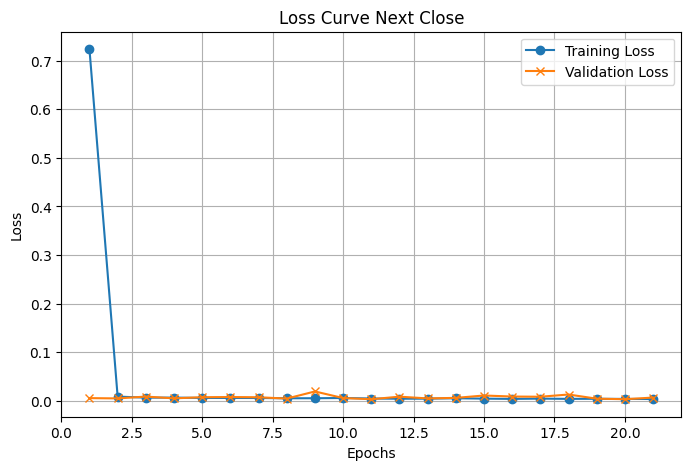

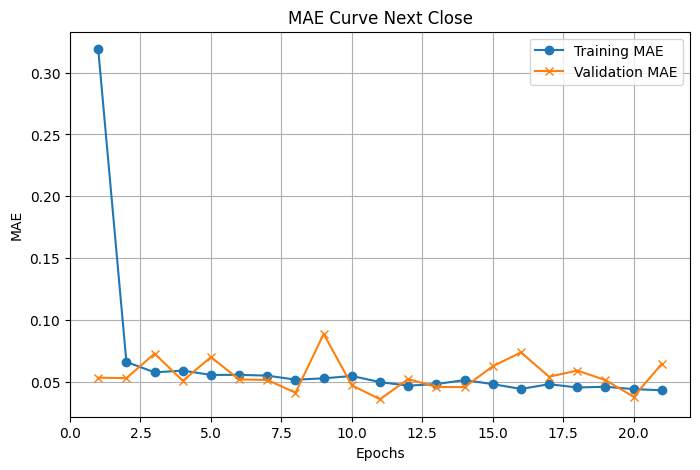

In [11]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Next Close')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Next Close')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
y_pred = model.predict([Xn_test,Xs_test])

y_test_real = np.expm1(y_test_seq).reshape(-1)
y_pred_real = np.expm1(y_pred).reshape(-1)

mae  = mean_absolute_error((y_test_real), (y_pred_real))
rmse = np.sqrt(mean_squared_error((y_test_real), (y_pred_real)))
mape = np.mean(np.abs(((y_test_real) - (y_pred_real)) / (y_test_real))) * 100
r2   = r2_score((y_test_real), (y_pred_real))
relative_mae = mae / np.mean(y_test_real) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE: {relative_mae:.2f}%")

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
MAE  : 7.99
RMSE : 17.69
MAPE : 15.38%
R²   : 0.986
Relative MAE: 6.09%
